# Supply Chain & Operations — Final Exam, Application 1
## Stock and Deliveries Pareto Curves (2025)

This notebook reproduces the two Pareto curves from the **Final exam** graphs, using their numerical values supplied in the accompanying dataset. It calculates cumulative percentages and ABCD classes, then exports charts and ranking tables.

**Classification rule:** A up to and including the SKU crossing 80%; B up to and including the SKU crossing 95%; C remaining positive values; D zero values.

In [1]:
import csv
from pathlib import Path
import matplotlib.pyplot as plt

# Output files are saved in the notebook working directory.
out = Path.cwd()

In [2]:
# Values from Application 1 (2025). SKUs not shown for a metric are zero.
stock = {
    'Alfa':3600, 'Beta':3000, 'Gamma':90, 'Delta':1200,
    'Epsilon':1950, 'Zeta':690, 'Eta':150, 'Teta':3300,
    'Iota':2850, 'Kappa':2610, 'Lambda':4950, 'Mu':30,
    'Xi':105, 'Omicron':495, 'Ro':2520,
}
deliveries = {
    'Alfa':6000, 'Beta':7800, 'Gamma':5850, 'Delta':2610,
    'Epsilon':2700, 'Eta':510, 'Teta':9600, 'Iota':5400,
    'Kappa':1500, 'Mu':810, 'Ni':1800, 'Xi':570,
    'Omicron':1620, 'Pi':2010, 'Ro':3750,
}
all_skus = sorted(set(stock) | set(deliveries))
stock = {sku: stock.get(sku, 0) for sku in all_skus}
deliveries = {sku: deliveries.get(sku, 0) for sku in all_skus}
print(f'{len(all_skus)} SKUs | Total average stock: {sum(stock.values()):,} | Total deliveries: {sum(deliveries.values()):,}')

17 SKUs | Total average stock: 27,540 | Total deliveries: 52,530


In [3]:
def pareto_rows(values):
    ranked = sorted(values.items(), key=lambda kv: (-kv[1], kv[0]))
    total = sum(values.values())
    if total <= 0:
        raise ValueError('Total metric must be positive.')
    cumulative = 0.0
    rows = []
    for rank, (sku, value) in enumerate(ranked, start=1):
        previous_pct = 100 * cumulative / total
        cumulative += value
        cls = ('D' if value == 0 else
               'A' if previous_pct < 80 else
               'B' if previous_pct < 95 else 'C')
        rows.append({'rank':rank, 'sku':sku, 'value':value,
                     'sku_pct':100 * rank / len(ranked),
                     'value_pct':100 * value / total,
                     'cumulative_pct':100 * cumulative / total,
                     'class':cls})
    return rows

def plot_pareto(rows, title, filename):
    x = [0] + [r['sku_pct'] for r in rows]
    y = [0] + [r['cumulative_pct'] for r in rows]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(x, y, marker='o', linewidth=2, markersize=4, label='Cumulative value')
    ax.plot([0, 100], [0, 100], linestyle=':', label='Equal distribution')
    ax.axhline(80, linestyle='--', label='80% boundary')
    ax.axhline(95, linestyle='--', label='95% boundary')
    ax.set(xlabel='Cumulative percentage of SKUs (%)',
           ylabel='Cumulative percentage of value (%)',
           title=title, xlim=(0,100), ylim=(0,105))
    ax.grid(alpha=0.25)
    ax.legend(loc='lower right')
    fig.tight_layout()
    fig.savefig(out / filename, dpi=220)
    plt.show()
    plt.close(fig)

def export_table(rows, filename):
    with (out / filename).open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

def print_table(rows):
    print('Rank  SKU           Value   Cum. %  Class')
    for r in rows:
        print(f"{r['rank']:>4}  {r['sku']:<10} {r['value']:>8,.0f}  {r['cumulative_pct']:>6.2f}%     {r['class']}")

## 1. Average Stock Pareto Curve

Rank  SKU           Value   Cum. %  Class
   1  Lambda        4,950   17.97%     A
   2  Alfa          3,600   31.05%     A
   3  Teta          3,300   43.03%     A
   4  Beta          3,000   53.92%     A
   5  Iota          2,850   64.27%     A
   6  Kappa         2,610   73.75%     A
   7  Ro            2,520   82.90%     A
   8  Epsilon       1,950   89.98%     B
   9  Delta         1,200   94.34%     B
  10  Zeta            690   96.84%     B
  11  Omicron         495   98.64%     C
  12  Eta             150   99.18%     C
  13  Xi              105   99.56%     C
  14  Gamma            90   99.89%     C
  15  Mu               30  100.00%     C
  16  Ni                0  100.00%     D
  17  Pi                0  100.00%     D


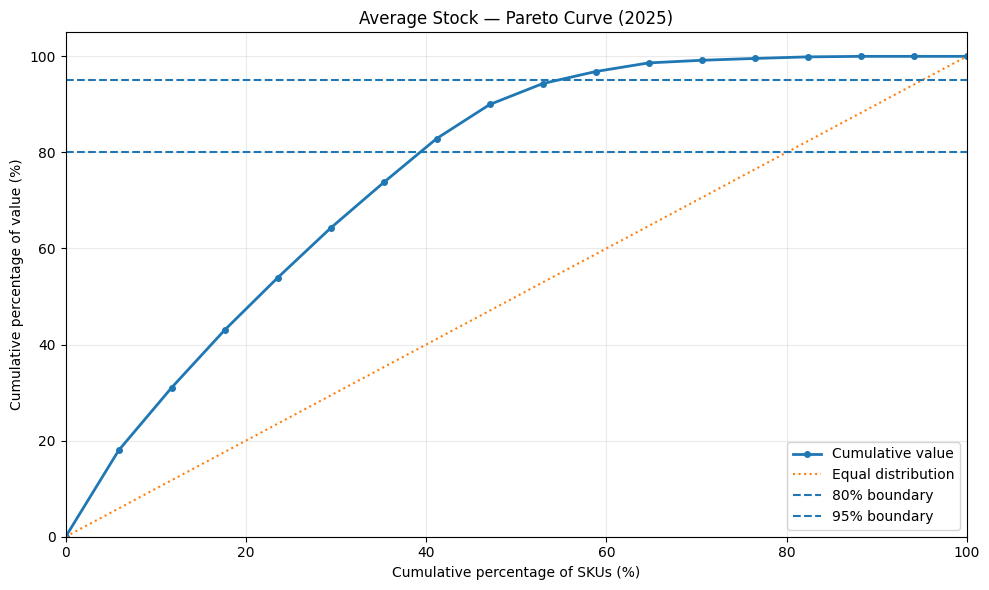

In [4]:
stock_rows = pareto_rows(stock)
print_table(stock_rows)
plot_pareto(stock_rows, 'Average Stock — Pareto Curve (2025)', 'Lafi_Pareto_Stock.png')
export_table(stock_rows, 'Lafi_Pareto_Average_Stock.csv')

## 2. Total Deliveries Pareto Curve

Rank  SKU           Value   Cum. %  Class
   1  Teta          9,600   18.28%     A
   2  Beta          7,800   33.12%     A
   3  Alfa          6,000   44.55%     A
   4  Gamma         5,850   55.68%     A
   5  Iota          5,400   65.96%     A
   6  Ro            3,750   73.10%     A
   7  Epsilon       2,700   78.24%     A
   8  Delta         2,610   83.21%     A
   9  Pi            2,010   87.04%     B
  10  Ni            1,800   90.46%     B
  11  Omicron       1,620   93.55%     B
  12  Kappa         1,500   96.40%     B
  13  Mu              810   97.94%     C
  14  Xi              570   99.03%     C
  15  Eta             510  100.00%     C
  16  Lambda            0  100.00%     D
  17  Zeta              0  100.00%     D


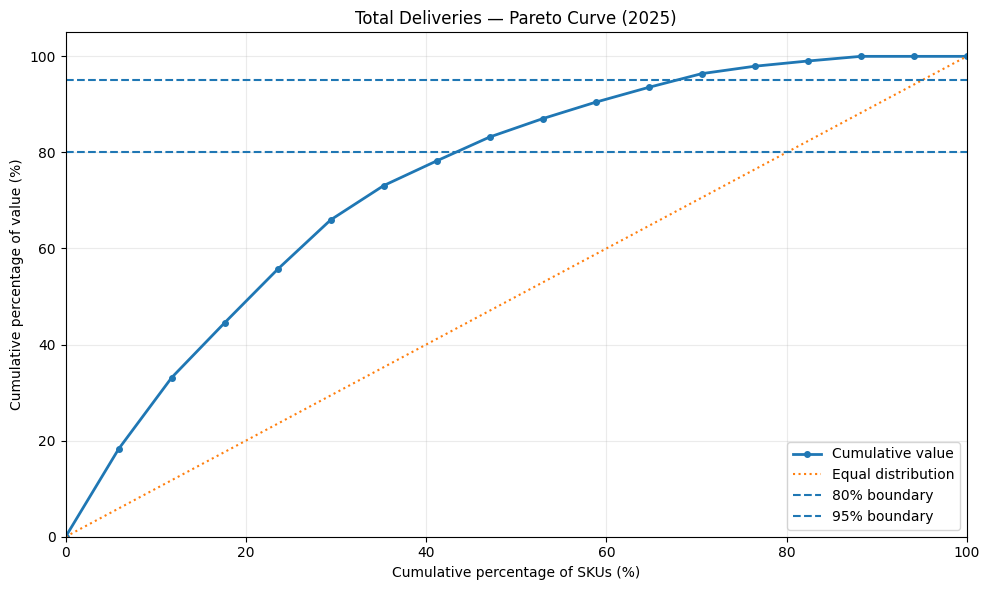

In [5]:
delivery_rows = pareto_rows(deliveries)
print_table(delivery_rows)
plot_pareto(delivery_rows, 'Total Deliveries — Pareto Curve (2025)', 'Lafi_Pareto_Deliveries.png')
export_table(delivery_rows, 'Lafi_Pareto_Total_Deliveries.csv')

#### Question 1:
The Pareto analysis of average stock and total deliveries reveals a moderate degree of skewness in both distributions.

Neither distribution is highly concentrated in a very small number of SKUs, nor are stock levels and deliveries uniformly distributed across all products.

Instead, a relatively broad group of SKUs accounts for approximately 80% of the total stock and deliveries, indicating a moderate concentration.

Therefore, both Pareto curves can be classified as moderately skewed, neither highly nor weakly skewed.

This suggests that inventory management and operational planning should consider a relatively broad range of products rather than focusing exclusively on a few dominant SKUs.

## 3. Summary
Compare the concentration of average stock and deliveries, and use the two ABCD classifications in the next step (the Cross Matrix).

In [6]:

import pandas as pd
from collections import Counter
from IPython.display import display

# Count SKUs in each ABCD class
stock_counts = Counter(r["class"] for r in stock_rows)
delivery_counts = Counter(r["class"] for r in delivery_rows)

# Build the ABCD classification summary table
abcd_summary = pd.DataFrame({
    "Class": ["A", "B", "C", "D"],
    "Stock (SKUs)": [stock_counts.get(c, 0) for c in "ABCD"],
    "Deliveries (SKUs)": [delivery_counts.get(c, 0) for c in "ABCD"]
})

# Add total row
abcd_summary.loc[len(abcd_summary)] = [
    "Total",
    abcd_summary["Stock (SKUs)"].sum(),
    abcd_summary["Deliveries (SKUs)"].sum()
]

# Display the formatted table
display(
    abcd_summary.style
    .hide(axis="index")
    .set_caption("Application 1 – ABCD Classification")
    .set_table_styles([
        {"selector": "caption",
         "props": [("font-size", "16px"),
                   ("font-weight", "bold"),
                   ("text-align", "center")]},
        {"selector": "th",
         "props": [("text-align", "center")]},
        {"selector": "td",
         "props": [("text-align", "center")]}
    ])
)


Class,Stock (SKUs),Deliveries (SKUs)
A,7,8
B,3,4
C,5,3
D,2,2
Total,17,17


### Question 2:

The results show that Class A includes 7 SKUs for stock and 8 for deliveries, confirming that neither distribution is dominated by only a few products.

The classification is therefore consistent with the moderate skewness identified in Question 1.

Furthermore, differences between the stock and delivery classifications suggest that certain SKUs have inventory levels that are not proportional to their delivery volumes. These discrepancies will be investigated through the Inventory Cross Matrix and inventory turnover analysis in Question 3.

In [7]:
abcd_summary.to_csv("Lafi_ABCD_Classification.csv", index=False)

Inventory turnover formula
Inventory turnover measures how frequently inventory is renewed over the reference period.

Inventory Turnover = Total Annual Deliveries / Average Stock

Since our reference period is 2025, inventory turnover is expressed in times per year.



In [8]:

import pandas as pd
import numpy as np
from IPython.display import display

# Combine Stock and Delivery ABCD classifications
df = pd.DataFrame({
    "SKU": all_skus,
    "Stock": [stock[sku] for sku in all_skus],
    "Deliveries": [deliveries[sku] for sku in all_skus],
    "Stock Class": [
        next(r["class"] for r in stock_rows if r["sku"] == sku)
        for sku in all_skus
    ],
    "Delivery Class": [
        next(r["class"] for r in delivery_rows if r["sku"] == sku)
        for sku in all_skus
    ]
})

# Aggregate stock and deliveries by Cross Matrix cell
cells = df.groupby(
    ["Stock Class", "Delivery Class"]
)[["Stock", "Deliveries"]].sum()

# Calculate inventory turnover
cells["Inventory Turnover"] = (
    cells["Deliveries"] / cells["Stock"].replace(0, np.nan)
)

# Create the 4x4 Cross Matrix
cross_matrix = cells["Inventory Turnover"].unstack()

cross_matrix = cross_matrix.reindex(
    index=list("ABCD"),
    columns=list("ABCD")
)

# Display the result
display(
    cross_matrix.style
    .format("{:.2f}", na_rep="—")
    .set_caption("Inventory Turnover Cross Matrix — 2025")
)

# Export detailed calculations
cells.to_csv("Lafi_Inventory_Turnover_Details.csv")

# Export Cross Matrix
cross_matrix.to_csv("Lafi_Inventory_Cross_Matrix.csv")


Delivery Class,A,B,C,D
Stock Class,,,,
A,2.13,0.57,—,0.00
B,1.69,—,—,0.00
C,65.00,3.27,6.63,—
D,—,—,—,—


### Question 3 — Inventory Turnover Cross Matrix

The Inventory Cross Matrix combines the ABCD classifications of average stock and annual deliveries to assess inventory efficiency.

The overall inventory turnover is approximately **1.91 times per year**, although significant differences emerge across individual cells.

The AA cell shows a turnover of 2.13, indicating relatively balanced inventory management for the main stock and delivery contributors.

The CA cell, represented by Gamma, exhibits an exceptionally high turnover of 65.00, suggesting an order-driven production or replenishment strategy with very limited average stock.

Conversely, Kappa (AB) shows a low turnover of 0.57, indicating potentially excessive inventory relative to demand. Lambda (AD) and Zeta (BD) have zero turnover, suggesting potential obsolete or inactive stock.

Omicron (CB) exhibits a turnover of 3.27, indicating relatively limited inventory compared with its delivery volume.

Finally, the DB cell contains deliveries but no recorded average stock, making its turnover mathematically undefined.

Overall, the Cross Matrix highlights opportunities to improve inventory allocation, reduce slow-moving stock, and investigate the sustainability of high-turnover products.

#### Question 4:

### Assessment of the coherence of the following statements with the inventory analysis.

### a.	SKU ‘Gamma’ is ETO according to Wortmann classification;

Stock : 90 units
Deliveries : 5,850
Turnover : 65.00

Engineer-to-Order (ETO) products are engineered or customized in response to specific customer orders. Finished-goods inventory is therefore typically limited.

Gamma's extremely low stock and high annual deliveries are consistent with an order-driven strategy. However, the data alone cannot establish whether engineering actually takes place after receiving orders.

**Conclusion : Coherent.**


### b.	SKU ‘Kappa’ has been replaced by SKU ‘Iota’ in the company market mix two years ago;

Stock : 2610
Deliveries : 1500
Turnover : 0.57


Kappa has considerably lower deliveries and turnover than Iota, supporting the possibility of a product replacement. However, Kappa still records 1,500 deliveries in 2025, despite supposedly having been replaced two years earlier.

This could indicate residual demand, spare-parts requirements, contractual obligations, or incomplete phase-out.

**Conclusion : Partially coherent.**


### c.	SKU ‘Omicron’ is MTS according to Wortmann classification and it requires very long production lead-time.

Stock : 495
Deliveries : 1620
Turnover : 3.27

In an MTS system, production is based on demand forecasts, and finished goods are held in inventory to satisfy customer orders.

A very long production lead time generally increases the importance of appropriate inventory coverage.

Omicron's relatively low average stock and moderate delivery contribution raise concerns about stock availability and replenishment risk. The annual turnover alone, however, cannot prove that inventory is insufficient.

**Conclusion : Potentially incoherent or risky**